# Customer Churn Prediction — An Illustrative Pipeline

This notebook walks through a small, end-to-end pipeline for predicting customer churn:

1. **Load** the data
2. **Clean** the data (impute missing values)
3. **Transform** the data (dummy encoding of categorical variables)
4. **Select variables** with a filter (Fisher score) — keep the 20 most predictive ones
5. **Model**: Linear Regression and Logistic Regression, plus Logistic Regression with forward, backward and stepwise variable selection
6. **Evaluate** every model on accuracy and AUC
7. **Compare** the models with and without variable selection — in predictive power and in the variables they use
8. **Interpret** the models through their coefficients

### Dataset
We use the well-known **IBM Telco Customer Churn** dataset: 7,043 customers of a telecom company, with a `Churn` (Yes/No) column as the target. It is small, clean, mixes numeric and categorical variables, and contains a handful of genuine missing values — which makes it a good teaching dataset for exactly this pipeline.

- Source used below: `https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv`
- Mirror (if the link above ever moves): search Kaggle for **"Telco Customer Churn" (blastchar)** — it's the same dataset.

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score, roc_curve

RANDOM_STATE = 42
pd.set_option('display.max_columns', None)

## 1. Load the data

In [2]:
DATA_URL = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

df = pd.read_csv(DATA_URL)

print(f"Shape: {df.shape}")
df.head()

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
df.info()

## 2. Clean the data — impute missing values

`TotalCharges` is loaded as text because a handful of brand-new customers (`tenure == 0`) have an empty string instead of a number. Converting the column to numeric turns those blanks into proper, detectable missing values (`NaN`) that we can then impute — this mirrors the situation you'll run into with most real-world business datasets.

In [3]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

missing = df.isna().sum()
print("Missing values per column:")
print(missing[missing > 0])

Missing values per column:
TotalCharges    11
dtype: int64


In [4]:
# Drop the customer identifier (not a predictive feature) and encode the target as 0/1
df = df.drop(columns=['customerID'])
df['Churn'] = df['Churn'].map({'No': 0, 'Yes': 1})

numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns.drop('Churn')
categorical_cols = df.select_dtypes(include=['object']).columns

print("Numeric columns:", list(numeric_cols))
print("Categorical columns:", list(categorical_cols))

Numeric columns: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical columns: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [5]:
# Impute: median for numeric columns, most-frequent category for categorical columns.
# This general pattern works even if a dataset has missing categorical values too.
num_imputer = SimpleImputer(strategy='median')
df[numeric_cols] = num_imputer.fit_transform(df[numeric_cols])

cat_imputer = SimpleImputer(strategy='most_frequent')
df[categorical_cols] = cat_imputer.fit_transform(df[categorical_cols])

print("Missing values remaining:", df.isna().sum().sum())

Missing values remaining: 0


## 3. Transform the data — dummy encoding of categorical variables

Linear and logistic regression need numeric input, so each categorical column is expanded into 0/1 dummy columns with `pd.get_dummies`. We drop one category per variable (`drop_first=True`) to avoid the [dummy variable trap](https://en.wikipedia.org/wiki/Multicollinearity) (perfect multicollinearity between the dummies).

Dummy encoding can also leave behind **redundant columns** that carry exactly the same information. In this dataset, for example, `InternetService_No` is identical to each of the six `..._No internet service` dummies (customers without internet service, by definition, have none of the internet add-ons), and `MultipleLines_No phone service` is the mirror image of `PhoneService_Yes`. Redundant columns add nothing, but they make regression models numerically unstable — the model cannot decide how to split an effect between identical columns, and the stepwise procedures used later cannot even be fitted. We therefore keep one column of each redundant group, detecting them automatically as columns whose absolute correlation with an earlier column is 1.

In [6]:
df_encoded = pd.get_dummies(df, columns=list(categorical_cols), drop_first=True)

# Remove perfectly redundant columns (|correlation| = 1 with a column that comes earlier)
corr = df_encoded.drop(columns='Churn').corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
redundant = [col for col in upper.columns if (upper[col] > 0.9999).any()]
df_encoded = df_encoded.drop(columns=redundant)

print("Dropped redundant columns:", redundant)
print(f"Shape after dummy encoding: {df_encoded.shape}")
df_encoded.head()

Dropped redundant columns: ['MultipleLines_No phone service', 'OnlineSecurity_No internet service', 'OnlineBackup_No internet service', 'DeviceProtection_No internet service', 'TechSupport_No internet service', 'StreamingTV_No internet service', 'StreamingMovies_No internet service']
Shape after dummy encoding: (7043, 24)


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_Yes,InternetService_Fiber optic,InternetService_No,OnlineSecurity_Yes,OnlineBackup_Yes,DeviceProtection_Yes,TechSupport_Yes,StreamingTV_Yes,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0.0,1.0,29.85,29.85,0,False,True,False,False,False,False,False,False,True,False,False,False,False,False,False,True,False,True,False
1,0.0,34.0,56.95,1889.50,0,True,False,False,True,False,False,False,True,False,True,False,False,False,True,False,False,False,False,True
2,0.0,2.0,53.85,108.15,1,True,False,False,True,False,False,False,True,True,False,False,False,False,False,False,True,False,False,True
3,0.0,45.0,42.30,1840.75,0,True,False,False,False,False,False,False,True,False,True,True,False,False,True,False,False,False,False,False
4,0.0,2.0,70.70,151.65,1,False,False,False,True,False,True,False,False,False,False,False,False,False,False,False,True,False,True,False


## 4. Train/test split

In [7]:
X = df_encoded.drop(columns=['Churn'])
y = df_encoded['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print(f"Train size: {X_train.shape[0]}   Test size: {X_test.shape[0]}")
print(f"Churn rate — train: {y_train.mean():.3f}   test: {y_test.mean():.3f}")

Train size: 5634   Test size: 1409
Churn rate — train: 0.265   test: 0.265


## 5. Scale the features

We standardize *every* column — the numeric features and the 0/1 dummy columns alike — to zero mean and unit variance. Besides helping logistic regression converge faster, this has a second benefit we'll use later: once every feature is on the same scale, each fitted coefficient is automatically the effect of a *1-standard-deviation* change in that feature, so coefficients are directly comparable across features without any further rescaling (Section 11).

The scaler is fit on the training data only, then applied to the test data, to avoid leaking test-set information.

In [8]:
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index
)
X_test_scaled = pd.DataFrame(
    scaler.transform(X_test), columns=X_test.columns, index=X_test.index
)

## 6. Variable selection — a filter approach

Not every predictor is equally useful, and a more compact model is easier to explain, cheaper to maintain and less prone to overfitting. A **filter** approach to variable selection ranks every predictor with a simple, model-independent statistic that measures how well that single variable separates churners from non-churners, and then keeps the top-ranked ones. It is fast and easy to explain — but each variable is judged *in isolation*, so overlap between predictors and effects that only show up in combination are ignored.

We use the **Fisher score**:

$$F_j = \frac{\left(\mu_j^{(1)} - \mu_j^{(0)}\right)^2}{\left(\sigma_j^{(1)}\right)^2 + \left(\sigma_j^{(0)}\right)^2}$$

where $\mu_j^{(c)}$ and $\left(\sigma_j^{(c)}\right)^2$ are the mean and variance of variable $j$ among the customers of class $c$ (1 = churner, 0 = non-churner). The score is large when the average value of a variable differs a lot between churners and non-churners, relative to how spread out the values are within each group. As an alternative filter you can switch to the absolute **correlation** with the target by changing `FILTER_METHOD` below; for a 0/1 target the two rankings are usually quite similar.

The ranking is computed on the **training data only** — using the full dataset would leak information from the test set into the selection. We then keep the 20 highest-ranked variables.

In [9]:
TOP_K = 20                    # number of variables to keep
FILTER_METHOD = 'fisher'      # 'fisher' or 'correlation'


def fisher_score(X, y):
    """Fisher score of every column of X for a binary target y."""
    X1, X0 = X[y == 1], X[y == 0]
    return (X1.mean() - X0.mean()) ** 2 / (X1.var() + X0.var())


filter_table = pd.DataFrame({
    'Fisher score': fisher_score(X_train_scaled, y_train),
    'Abs. correlation': X_train_scaled.corrwith(y_train).abs(),
})
filter_table['Fisher rank'] = filter_table['Fisher score'].rank(ascending=False, method='min').astype(int)
filter_table['Correlation rank'] = filter_table['Abs. correlation'].rank(ascending=False, method='min').astype(int)

score_col = 'Fisher score' if FILTER_METHOD == 'fisher' else 'Abs. correlation'
rank_col = 'Fisher rank' if FILTER_METHOD == 'fisher' else 'Correlation rank'

filter_table = filter_table.sort_values(rank_col)
selected_features = filter_table.index[:TOP_K].tolist()
filter_table['Selected'] = ['✓' if f in selected_features else '' for f in filter_table.index]

print(f"Filter kept {len(selected_features)} of {len(filter_table)} variables.")
filter_table.round(4)

Filter kept 20 of 23 variables.


,Fisher score,Abs. correlation,Fisher rank,Correlation rank,Selected
tenure,0.3802,0.3456,1,1,✓
Contract_Two year,0.3533,0.3022,2,4,✓
InternetService_Fiber optic,0.2826,0.3127,3,2,✓
PaymentMethod_Electronic check,0.2541,0.3092,4,3,✓
InternetService_No,0.1793,0.2289,5,5,✓
MonthlyCharges,0.1160,0.1980,6,6,✓
PaperlessBilling_Yes,0.1117,0.1980,7,7,✓
TotalCharges,0.1102,0.1944,8,8,✓
Contract_One year,0.1016,0.1795,9,9,✓
OnlineSecurity_Yes,0.0903,0.1746,10,10,✓


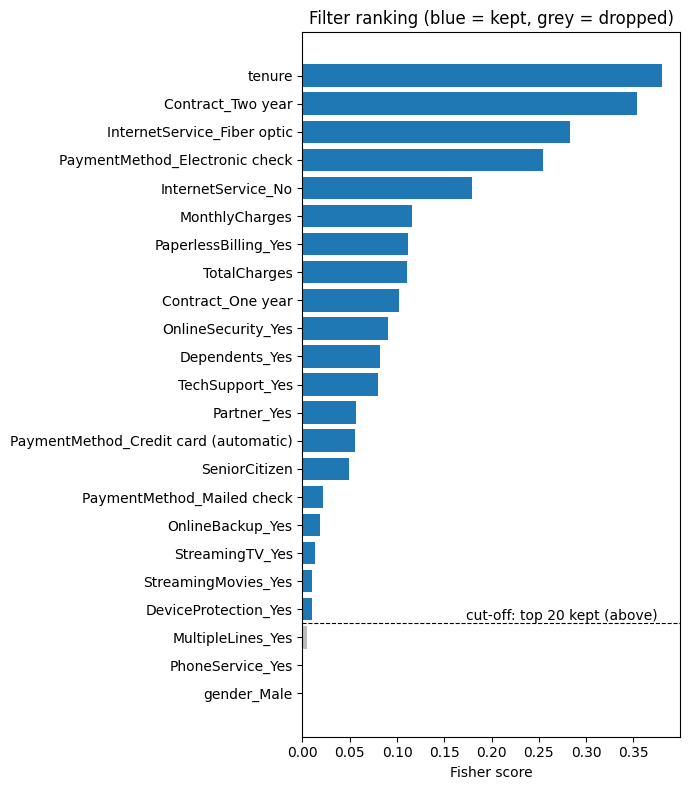

In [10]:
plot_df = filter_table.iloc[::-1]   # reverse so that rank 1 is plotted on top
colors = ['#1f77b4' if s == '✓' else '#bdbdbd' for s in plot_df['Selected']]

cutoff = len(plot_df) - TOP_K - 0.5   # position of the cut-off line between rank TOP_K and rank TOP_K + 1

plt.figure(figsize=(7, 8))
plt.barh(plot_df.index, plot_df[score_col], color=colors)
plt.axhline(cutoff, color='black', linestyle='--', linewidth=0.8)
plt.text(plot_df[score_col].max(), cutoff, f'cut-off: top {TOP_K} kept (above) ', ha='right', va='bottom')
plt.xlabel(score_col)
plt.title('Filter ranking (blue = kept, grey = dropped)')
plt.tight_layout()
plt.show()

## 7. Linear Regression

From here on every model is developed twice, so that the impact of variable selection can be seen: once **without variable selection** (all predictors) and once **with variable selection** (only the predictors kept by the filter). A small helper function evaluates each model on the test set and stores the result for the comparison in Section 10.

Linear regression treats the 0/1 churn indicator as a continuous target (a *linear probability model*). It is not designed for classification — its predictions aren't bounded between 0 and 1 — but fitting it here is instructive: it gives us a natural baseline to compare against logistic regression.

In [11]:
model_results = {}   # test-set performance of every model, collected for the comparison in Section 10


def evaluate_and_store(model, selection, scores, features):
    """Evaluate a model on the test set and store the result.

    scores   : continuous model output for the test customers (a predicted probability,
               or the raw prediction in the case of linear regression)
    features : the variables the model uses

    Accuracy uses a 0.5 cut-off on the scores; AUC uses the scores directly, since it only
    depends on how well they rank churners above non-churners.
    """
    scores = np.asarray(scores)
    accuracy = accuracy_score(y_test, (scores >= 0.5).astype(int))
    auc = roc_auc_score(y_test, scores)
    model_results[(model, selection)] = {
        'features': list(features), 'scores': scores, 'Accuracy': accuracy, 'AUC': auc,
    }
    print(f"{model:<20} | {selection:<18} | {len(features):>2} variables | Accuracy: {accuracy:.3f}   AUC: {auc:.3f}")

In [12]:
# Without variable selection: all predictors
lin_reg = LinearRegression()
lin_reg.fit(X_train_scaled, y_train)

# Raw, unbounded predictions. AUC only needs scores that rank customers correctly, so these can be
# used directly; for accuracy they are cut at 0.5 inside the helper function.
y_pred_lin_continuous = lin_reg.predict(X_test_scaled)
evaluate_and_store('Linear regression', 'None', y_pred_lin_continuous, X_train_scaled.columns)

Linear regression    | None               | 23 variables | Accuracy: 0.796   AUC: 0.830


In [13]:
# With variable selection: only the predictors kept by the filter
lin_reg_filter = LinearRegression()
lin_reg_filter.fit(X_train_scaled[selected_features], y_train)

y_pred_lin_filter = lin_reg_filter.predict(X_test_scaled[selected_features])
evaluate_and_store('Linear regression', 'Filter', y_pred_lin_filter, selected_features)

Linear regression    | Filter             | 20 variables | Accuracy: 0.794   AUC: 0.830


## 8. Logistic Regression

Logistic regression models the log-odds of churn as a linear function of the features, which keeps predicted probabilities in [0, 1] — the natural choice for a binary target.

A note on the estimator: scikit-learn's `LogisticRegression` applies a mild L2 penalty by default. Here we set a very large `C` (= practically no penalty), which gives plain maximum-likelihood logistic regression — the same estimator that the stepwise procedures in Section 9 use. Differences between the models then reflect the choice of variables only, not a difference in estimation method.

In [14]:
# Without variable selection: all predictors
log_reg = LogisticRegression(C=1e6, max_iter=1000)   # very large C = (practically) no regularization
log_reg.fit(X_train_scaled, y_train)

y_pred_log_proba = log_reg.predict_proba(X_test_scaled)[:, 1]
evaluate_and_store('Logistic regression', 'None', y_pred_log_proba, X_train_scaled.columns)

Logistic regression  | None               | 23 variables | Accuracy: 0.801   AUC: 0.841


In [15]:
# With variable selection: only the predictors kept by the filter
log_reg_filter = LogisticRegression(C=1e6, max_iter=1000)
log_reg_filter.fit(X_train_scaled[selected_features], y_train)

y_pred_log_filter = log_reg_filter.predict_proba(X_test_scaled[selected_features])[:, 1]
evaluate_and_store('Logistic regression', 'Filter', y_pred_log_filter, selected_features)

Logistic regression  | Filter             | 20 variables | Accuracy: 0.796   AUC: 0.841


## 9. Logistic regression with forward, backward and stepwise variable selection

The filter judges every variable *on its own*. A **wrapper** approach instead builds the model while selecting, and judges each variable by its contribution *given the other variables already in the model*. Three classic procedures, all driven by the p-value of a variable in a logistic regression (Wald test), all run on the training data only, and all starting from the 20 variables that survived the filter:

- **Forward selection** starts with no variables and repeatedly adds the variable with the smallest p-value, as long as that p-value is below `P_ENTER`.
- **Backward elimination** starts with all variables and repeatedly removes the variable with the largest p-value, as long as that p-value is above `P_REMOVE`.
- **Stepwise selection** is forward selection with a safety check: after every addition, the variables already in the model are re-tested, and any whose p-value has risen above `P_REMOVE` is removed again (a variable that looked useful early on can become redundant once other variables join).

P-values are not available in scikit-learn, so these fits use `statsmodels` (maximum-likelihood logistic regression, the same model as in Section 8). scikit-learn's `SequentialFeatureSelector` offers cross-validation-based forward and backward selection, but no stepwise variant.

In [16]:
P_ENTER = 0.05    # a variable may enter the model if its p-value is below this level
P_REMOVE = 0.05   # a variable is removed from the model if its p-value is above this level


def fit_logit(cols):
    """Logistic regression (maximum likelihood) of churn on the given columns of the training data."""
    exog = sm.add_constant(X_train_scaled[cols], has_constant='add')
    return sm.Logit(y_train, exog).fit(disp=0)


def candidate_pvalue(selected, candidate):
    """p-value of `candidate` when it is added to the current model (None if the model cannot be fitted)."""
    try:
        with warnings.catch_warnings():
            warnings.simplefilter('ignore')
            p = fit_logit(selected + [candidate]).pvalues[candidate]
        return p if np.isfinite(p) else None
    except Exception:       # e.g. singular matrix or perfect separation: skip this candidate
        return None


def forward_selection(candidates, p_enter=P_ENTER, verbose=True):
    selected = []
    while True:
        pvals = {c: candidate_pvalue(selected, c) for c in candidates if c not in selected}
        pvals = {c: p for c, p in pvals.items() if p is not None}
        if not pvals:
            break
        best = min(pvals, key=pvals.get)
        if pvals[best] >= p_enter:
            break
        selected.append(best)
        if verbose:
            print(f"  + {best:<40} p = {pvals[best]:.4f}")
    return selected


def backward_elimination(candidates, p_remove=P_REMOVE, verbose=True):
    selected = list(candidates)
    while selected:
        pvals = fit_logit(selected).pvalues.drop('const')
        worst = pvals.idxmax()
        if pvals[worst] <= p_remove:
            break
        selected.remove(worst)
        if verbose:
            print(f"  - {worst:<40} p = {pvals[worst]:.4f}")
    return selected


def stepwise_selection(candidates, p_enter=P_ENTER, p_remove=P_REMOVE, verbose=True, max_steps=100):
    selected = []
    for _ in range(max_steps):
        changed = False

        # Forward step: add the most significant candidate, if it is significant enough
        pvals = {c: candidate_pvalue(selected, c) for c in candidates if c not in selected}
        pvals = {c: p for c, p in pvals.items() if p is not None}
        if pvals:
            best = min(pvals, key=pvals.get)
            if pvals[best] < p_enter:
                selected.append(best)
                changed = True
                if verbose:
                    print(f"  + {best:<40} p = {pvals[best]:.4f}")

        # Backward step: re-test the variables already in the model, remove the least significant if needed
        if selected:
            p_in_model = fit_logit(selected).pvalues.drop('const')
            worst = p_in_model.idxmax()
            if p_in_model[worst] > p_remove:
                selected.remove(worst)
                changed = True
                if verbose:
                    print(f"  - {worst:<40} p = {p_in_model[worst]:.4f}")

        if not changed:
            break
    return selected

In [17]:
print("Forward selection:")
forward_features = forward_selection(selected_features)

print("\nBackward elimination:")
backward_features = backward_elimination(selected_features)

print("\nStepwise selection:")
stepwise_features = stepwise_selection(selected_features)

print(f"\nVariables kept — forward: {len(forward_features)}, backward: {len(backward_features)}, stepwise: {len(stepwise_features)}")

Forward selection:
  + tenure                                   p = 0.0000
  + InternetService_Fiber optic              p = 0.0000
  + PaymentMethod_Electronic check           p = 0.0000
  + InternetService_No                       p = 0.0000
  + Contract_Two year                        p = 0.0000
  + Contract_One year                        p = 0.0000
  + PaperlessBilling_Yes                     p = 0.0000
  + OnlineSecurity_Yes                       p = 0.0000
  + StreamingMovies_Yes                      p = 0.0000
  + TechSupport_Yes                          p = 0.0002
  + TotalCharges                             p = 0.0007
  + StreamingTV_Yes                          p = 0.0079
  + MonthlyCharges                           p = 0.0028
  + Dependents_Yes                           p = 0.0080

Backward elimination:
  - PaymentMethod_Credit card (automatic)    p = 0.7770
  - DeviceProtection_Yes                     p = 0.7356
  - Partner_Yes                              p = 0.7206
  - Pa

In [18]:
# Evaluate the three selected models on the test set
for label, feats in [('Filter + forward', forward_features),
                     ('Filter + backward', backward_features),
                     ('Filter + stepwise', stepwise_features)]:
    final_model = fit_logit(feats)
    test_scores = final_model.predict(sm.add_constant(X_test_scaled[feats], has_constant='add'))
    evaluate_and_store('Logistic regression', label, test_scores, feats)

Logistic regression  | Filter + forward   | 14 variables | Accuracy: 0.798   AUC: 0.840
Logistic regression  | Filter + backward  | 14 variables | Accuracy: 0.798   AUC: 0.840
Logistic regression  | Filter + stepwise  | 14 variables | Accuracy: 0.798   AUC: 0.840


Because these models come from `statsmodels`, we also get a full coefficient table for free. Below is the final **stepwise** model, with the effect of each remaining variable (per 1-SD change), the corresponding odds ratio and its p-value.

In [19]:
final_stepwise = fit_logit(stepwise_features)

stepwise_summary = pd.DataFrame({
    'Coefficient (log-odds per 1-SD)': final_stepwise.params,
    'Odds ratio per 1-SD change': np.exp(final_stepwise.params),
    'p-value': final_stepwise.pvalues,
}).drop(index='const').sort_values('p-value')

stepwise_summary.round(4)

,Coefficient (log-odds per 1-SD),Odds ratio per 1-SD change,p-value
tenure,-1.2554,0.2849,0.0000
Contract_Two year,-0.6087,0.5441,0.0000
InternetService_No,-0.5271,0.5903,0.0000
Contract_One year,-0.3006,0.7404,0.0000
InternetService_Fiber optic,0.6159,1.8513,0.0000
PaymentMethod_Electronic check,0.1834,1.2013,0.0000
PaperlessBilling_Yes,0.1895,1.2087,0.0000
StreamingMovies_Yes,0.1998,1.2211,0.0001
StreamingTV_Yes,0.1973,1.2182,0.0001
OnlineSecurity_Yes,-0.1618,0.8506,0.0003


## 10. Compare the models — with and without variable selection

Two questions matter when comparing the models:

1. **Predictive power** — accuracy and AUC on the test set, which played no role in the filter, in the stepwise procedures or in fitting the models.
2. **Selected variables** — how many variables each approach keeps, and whether the approaches agree on which ones.

In [20]:
comparison = pd.DataFrame([
    {'Model': model, 'Variable selection': selection, '# variables': len(r['features']),
     'Accuracy': r['Accuracy'], 'AUC': r['AUC']}
    for (model, selection), r in model_results.items()
])
comparison.round(3)

,Model,Variable selection,# variables,Accuracy,AUC
0,Linear regression,None,23,0.796,0.830
1,Linear regression,Filter,20,0.794,0.830
2,Logistic regression,None,23,0.801,0.841
3,Logistic regression,Filter,20,0.796,0.841
4,Logistic regression,Filter + forward,14,0.798,0.840
5,Logistic regression,Filter + backward,14,0.798,0.840
6,Logistic regression,Filter + stepwise,14,0.798,0.840


In [ ]:
plt.figure(figsize=(7, 7))
for (model, selection), r in model_results.items():
    fpr, tpr, _ = roc_curve(y_test, r['scores'])
    plt.plot(fpr, tpr, linewidth=1.5, label=f"{model} – {selection} (AUC = {r['AUC']:.3f})")
plt.plot([0, 1], [0, 1], linestyle='--', color='grey', label='Random guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC curves — with and without variable selection')
plt.legend(fontsize=8, loc='lower right')
plt.show()

### Which variables does each approach select?

The table lists all candidate predictors, ordered by their filter rank, and marks with a ✓ the variables used by each logistic regression model.

In [21]:
selection_sets = {
    'No selection': list(X_train_scaled.columns),
    'Filter': selected_features,
    'Filter + forward': forward_features,
    'Filter + backward': backward_features,
    'Filter + stepwise': stepwise_features,
}

variable_matrix = pd.DataFrame(
    {name: ['✓' if f in feats else '' for f in filter_table.index] for name, feats in selection_sets.items()},
    index=filter_table.index,
)
variable_matrix.insert(0, 'Filter rank', filter_table[rank_col])
variable_matrix.loc['Number of variables'] = [''] + [len(feats) for feats in selection_sets.values()]
variable_matrix

,Filter rank,No selection,Filter,Filter + forward,Filter + backward,Filter + stepwise
tenure,1,✓,✓,✓,✓,✓
Contract_Two year,2,✓,✓,✓,✓,✓
InternetService_Fiber optic,3,✓,✓,✓,✓,✓
PaymentMethod_Electronic check,4,✓,✓,✓,✓,✓
InternetService_No,5,✓,✓,✓,✓,✓
MonthlyCharges,6,✓,✓,✓,✓,✓
PaperlessBilling_Yes,7,✓,✓,✓,✓,✓
TotalCharges,8,✓,✓,✓,✓,✓
Contract_One year,9,✓,✓,✓,✓,✓
OnlineSecurity_Yes,10,✓,✓,✓,✓,✓


In [22]:
wrapper_sets = {'forward': set(forward_features), 'backward': set(backward_features), 'stepwise': set(stepwise_features)}

dropped_by_filter = [f for f in X_train_scaled.columns if f not in selected_features]
in_all_three = [f for f in selected_features if all(f in s for s in wrapper_sets.values())]
in_none = [f for f in selected_features if not any(f in s for s in wrapper_sets.values())]
in_some = [f for f in selected_features if f not in in_all_three and f not in in_none]

print(f"Dropped by the filter ({len(dropped_by_filter)}):")
print("   ", dropped_by_filter)

print(f"\nKept by the filter, and by all three wrapper methods ({len(in_all_three)}):")
print("   ", in_all_three)

print(f"\nKept by the filter, but by only some of the wrapper methods ({len(in_some)}):")
for f in in_some:
    print(f"    {f:<40} kept by: {', '.join(name for name, s in wrapper_sets.items() if f in s)}")

print(f"\nKept by the filter, but dropped by all three wrapper methods ({len(in_none)}):")
print("   ", in_none)

Dropped by the filter (3):
    ['gender_Male', 'PhoneService_Yes', 'MultipleLines_Yes']

Kept by the filter, and by all three wrapper methods (14):
    ['tenure', 'Contract_Two year', 'InternetService_Fiber optic', 'PaymentMethod_Electronic check', 'InternetService_No', 'MonthlyCharges', 'PaperlessBilling_Yes', 'TotalCharges', 'Contract_One year', 'OnlineSecurity_Yes', 'Dependents_Yes', 'TechSupport_Yes', 'StreamingTV_Yes', 'StreamingMovies_Yes']

Kept by the filter, but by only some of the wrapper methods (0):

Kept by the filter, but dropped by all three wrapper methods (6):
    ['Partner_Yes', 'PaymentMethod_Credit card (automatic)', 'SeniorCitizen', 'PaymentMethod_Mailed check', 'OnlineBackup_Yes', 'DeviceProtection_Yes']


**How to read these results.** Variable selection trades a — usually small — amount of predictive power for a more compact model that is easier to explain, monitor and maintain. If the AUC and accuracy of the models with selection are close to those of the models without it while the number of variables drops, the removed variables were adding complexity rather than predictive power. The variable table shows where the approaches differ: the filter drops variables that are weak *on their own*, whereas the wrapper methods also drop variables that are redundant *given the other variables* (for example, a variable that overlaps with another that is already in the model). The three wrapper methods are greedy — each step is the best one locally, with no guarantee of finding the best subset overall — so they can end up with different variables, and variables that are only marginally significant are the ones most likely to differ.

## 11. Interpreting the models — ranking variables by importance

Because every feature was standardized before fitting (Section 5), the fitted coefficients are already on one common scale: each one is the effect of a *1-standard-deviation* change in that feature — the numeric features and the 0/1 dummy columns alike — on the outcome (linear regression) or on the log-odds of churn (logistic regression). That means we can rank variables by the raw coefficient magnitude directly, with no further rescaling needed. The table below uses the models fitted on all variables (Sections 7 and 8); the final stepwise model in Section 9 has its own coefficient table.

For logistic regression we additionally convert each coefficient into an **odds ratio** (`exp(coefficient)`), which is usually the easiest way to talk about the effect in business terms: an odds ratio of 1.4 means a 1-SD increase in that feature multiplies the odds of churn by 1.4×; an odds ratio below 1 means it lowers the odds. For a 0/1 dummy, note that "a 1-SD change" means a shift in *how common* that attribute is across customers (its std is √(p·(1−p))), not a full switch from 0 to 1 — worth keeping in mind when interpreting a dummy variable's effect specifically.

In [23]:
coef_table = pd.DataFrame({
    'Feature': X.columns,
    'Linear coef. (standardized)': lin_reg.coef_,
    'Logistic coef. (standardized, log-odds)': log_reg.coef_[0],
})
coef_table['Odds ratio per 1-SD change'] = np.exp(coef_table['Logistic coef. (standardized, log-odds)'])

# Rank by the size of the standardized logistic coefficient — i.e. how much
# a 1-SD change in the feature moves the log-odds of churn, up or down
coef_table['Abs. importance (logistic)'] = coef_table['Logistic coef. (standardized, log-odds)'].abs()
coef_table = coef_table.sort_values('Abs. importance (logistic)', ascending=False).reset_index(drop=True)

top_n = 15
coef_table.drop(columns='Abs. importance (logistic)').head(top_n)

,Feature,Linear coef. (standardized),"Logistic coef. (standardized, log-odds)",Odds ratio per 1-SD change
0,MonthlyCharges,-0.225114,-2.558936,0.077387
1,InternetService_Fiber optic,0.184629,1.446969,4.250212
2,tenure,-0.035442,-1.303200,0.271661
3,InternetService_No,-0.138807,-1.206192,0.299335
4,Contract_Two year,-0.032142,-0.591849,0.553304
5,TotalCharges,-0.110952,0.580630,1.787165
6,StreamingMovies_Yes,0.063382,0.520334,1.682589
7,StreamingTV_Yes,0.063354,0.518960,1.680279
8,MultipleLines_Yes,0.046294,0.350094,1.419201
9,PhoneService_Yes,0.037006,0.334226,1.396859


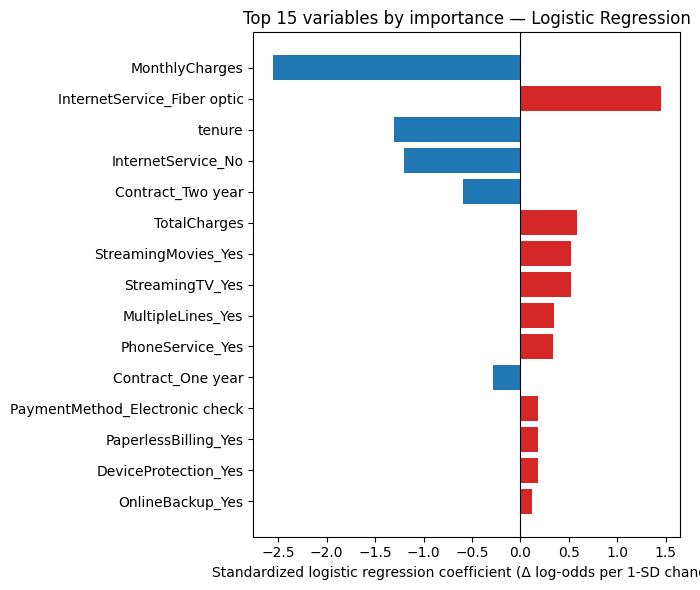

In [24]:
top = coef_table.head(top_n).iloc[::-1]  # reverse so the most important feature plots on top
colors = ['#d62728' if v > 0 else '#1f77b4' for v in top['Logistic coef. (standardized, log-odds)']]

plt.figure(figsize=(7, 6))
plt.barh(top['Feature'], top['Logistic coef. (standardized, log-odds)'], color=colors)
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel('Standardized logistic regression coefficient (Δ log-odds per 1-SD change)')
plt.title(f'Top {top_n} variables by importance — Logistic Regression')
plt.tight_layout()
plt.show()

A couple of caveats worth flagging (especially with a dummy-encoded dataset like this one):

- **These are coefficients from a single model fit, not causal effects.** Many predictors are still correlated with each other (e.g. `tenure` and `TotalCharges`, or `MonthlyCharges` and `InternetService_Fiber optic`), so a coefficient partly reflects *other correlated features being held fixed* rather than an isolated, actionable effect. Treat the ranking as a description of association, not a recommendation for which lever to pull.
- **Regularization helps when features are correlated.** The logistic regression above is (practically) unpenalized. If you need a more stable ranking, refit with a stronger L2 or L1 penalty (a smaller `C`) and compare — coefficient rankings that survive regularization are usually more trustworthy.
- **Statistical significance is a separate question from importance.** The stepwise model in Section 9 reports p-values for its variables. Keep in mind that p-values reported *after* a data-driven selection are optimistic, because the same data were used to choose the variables.

## Wrap-up

Both models produce a ranking of customers by churn risk (comparable AUC), but only logistic regression produces predictions that behave like probabilities — which matters as soon as you want to act on the scores (e.g. rank customers for a retention campaign, or set a business-driven decision threshold instead of the default 0.5). This is why logistic regression, not linear regression, is the standard choice for binary classification, and why linear regression was included above mainly for illustration and comparison.

Variable selection adds a second lens: a **filter** is fast, model-independent and easy to explain, but looks at one variable at a time; **wrapper** methods such as forward, backward and stepwise selection take the interplay between variables into account, but are greedy, computationally heavier and can disagree with each other. Section 10 shows what each of them costs and buys on this dataset.

Natural next steps for a real project:
- Run the forward, backward and stepwise procedures on *all* variables (without the filter first) and compare with the filter-then-wrapper route used here.
- Try an *embedded* selection method such as an L1-regularized (lasso) logistic regression, or cross-validation-based selection with scikit-learn's `SequentialFeatureSelector`, and check whether the selected variables are stable across different train/test splits.
- Handle class imbalance (the churn rate is well under 50%) with class weights or resampling.
- Try other classifiers (trees, gradient boosting) as benchmarks, and validate the coefficient-based ranking with a model-agnostic importance method (e.g. permutation importance, SHAP).
- Replace the default 0.5 threshold with one chosen from the actual costs and benefits of retention actions (a cost- or profit-driven cutoff), rather than a purely statistical one.